In [1]:
def plot_probes(ax, leak):
    """A: within-slot vs cross-slot probe accuracy (chance-adjusted)."""
    x = np.arange(len(leak)); w = 0.38
    within = leak.within_slot_adjusted_balanced_accuracy
    cross = leak.cross_slot_adjusted_balanced_accuracy
    ax.bar(x - w/2, within, w, color=NAVY, label="within slot")
    ax.bar(x + w/2, cross, w, color=GREEN, label="other slot (leakage)")
    for xi, a, b in zip(x, within, cross):
        ax.text(xi - w/2, a + 0.02, f"{a:.2f}", ha="center", fontsize=10)
        ax.text(xi + w/2, max(b, 0) + 0.02, f"{b:.2f}", ha="center", fontsize=10)
    ax.axhline(0, color=GREY, lw=1)
    ax.set_xticks(x, leak.target_factor)
    ax.set_ylim(-0.08, 1.28)
    ax.set_ylabel("chance-adjusted balanced accuracy")
    ax.set_title("A  Linear probes: own slot vs other slot", loc="left", fontweight="bold")
    ax.legend(frameon=False, loc="upper center", ncol=2, fontsize=10)


def plot_orthogonality_matrix(ax, omat):
    """B: mean |cosine| between factors (diagonal = within, off-diagonal = across)."""
    labels = [short(c) for c in omat.columns]
    im = ax.imshow(omat.values, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(labels)), labels, rotation=30, ha="right")
    ax.set_yticks(range(len(labels)), labels)
    for i in range(len(labels)):
        for j in range(len(labels)):
            v = omat.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                    color="white" if v > 0.5 else "black")
    ax.set_title("B  Mean |cosine| between factors", loc="left", fontweight="bold")
    ax.spines[:].set_visible(False)
    return im


def plot_principal_angles(ax, ovl):
    """C: principal angles between factor subspaces (mean, with min-max range)."""
    pair = [f"{short(a)} – {short(b)}" for a, b in zip(ovl.factor_a, ovl.factor_b)]
    y = np.arange(len(ovl))[::-1]
    ax.hlines(y, ovl.minimum_principal_angle_degrees, ovl.maximum_principal_angle_degrees,
              color=LIGHT, lw=8)
    ax.scatter(ovl.mean_principal_angle_degrees, y, color=NAVY, zorder=3, s=60)
    ax.axvline(90, color=GREY, ls="--", lw=1)
    ax.text(89, y.min() - 0.75, "90° = orthogonal", ha="right", color=GREY, fontsize=10)
    for yi, o in zip(y, ovl.subspace_overlap):
        ax.text(93, yi, f"overlap {o:.2f}", va="center", fontsize=10, color=GREY)
    ax.set_yticks(y, pair)
    ax.set_xlim(0, 118)
    ax.set_ylim(y.min() - 1.0, y.max() + 0.6)
    ax.set_xlabel("principal angle (degrees)")
    ax.set_title("C  Angles between factor subspaces", loc="left", fontweight="bold")


def plot_dimensionality(ax, fdim, odim):
    """D: effective rank and k95 per factor, plus the overall numbers."""
    f = [short(n) for n in fdim.factor]; xx = np.arange(len(f))
    ax.bar(xx, fdim.effective_rank, color=NAVY, width=0.55, label="effective rank")
    ax.scatter(xx, fdim.k95, marker="D", color=GREEN, s=70, zorder=3, label="k95")
    for xi, er in zip(xx, fdim.effective_rank):
        ax.text(xi, er + 0.06, f"{er:.2f}", ha="center", fontsize=10)
    ax.set_xticks(xx, f, rotation=15)
    ax.set_ylim(0, max(fdim.k95.max(), fdim.effective_rank.max()) + 1.6)
    ax.set_ylabel("dimensions")
    ax.set_title("D  Dimensionality per factor", loc="left", fontweight="bold")
    ax.legend(frameon=False, loc="upper left", fontsize=10)
    ax.text(0.98, 0.98,
            f"overall: effective dim {odim.effective_dimensionality:.2f}\n"
            f"k95 = {int(odim.k95)} of {int(odim.total_components)} "
            f"({odim.variance_explained_by_k95:.1%} variance)",
            transform=ax.transAxes, ha="right", va="top", fontsize=10,
            bbox=dict(boxstyle="round", fc="#F3F4F6", ec="none"))


def plot_factorisation(ax, fac):
    """E: R² of the factorisation (raw, projected, projected+whitened)."""
    names = ["raw", "projected", "projected\nwhitened"]
    vals = [fac.raw_r2, fac.projected_r2, fac.projected_whitened_r2]
    bars = ax.bar(names, vals, color=[LIGHT, LIGHT, NAVY], width=0.55)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, v + 0.02, f"{v:.2f}", ha="center")
    ax.set_ylim(0, 1.2)
    ax.set_ylabel("R²")
    ax.set_title("E  Factorisation (R²)", loc="left", fontweight="bold")
    ax.text(0.98, 0.95,
            f"primary metric = {fac.primary_factorisation_metric}\n"
            f"probe span rank = {int(fac.probe_span_rank)}",
            transform=ax.transAxes, ha="right", va="top", fontsize=10, color=GREY)


def plot_orthogonality_summary(ax, osum):
    """F: mean |cosine| within vs across factors."""
    vals = [osum.mean_within_factor_absolute_cosine, osum.mean_across_factor_absolute_cosine]
    ns = [osum.n_within_comparisons, osum.n_across_comparisons]
    bars = ax.bar(["within factor", "across factors"], vals, color=[LIGHT, NAVY], width=0.5)
    for b, v, n in zip(bars, vals, ns):
        ax.text(b.get_x() + b.get_width()/2, v + 0.02, f"{v:.2f}\n(n={int(n):,})",
                ha="center", fontsize=10)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("mean |cosine|")
    ax.set_title("F  Orthogonality summary", loc="left", fontweight="bold")

Reading from: /mnt/primary/compositional-ood-generalization/DS/two-sprite-compositional-learning/analysis_results_gpu/diagonal_compositional/intermediate/slot2


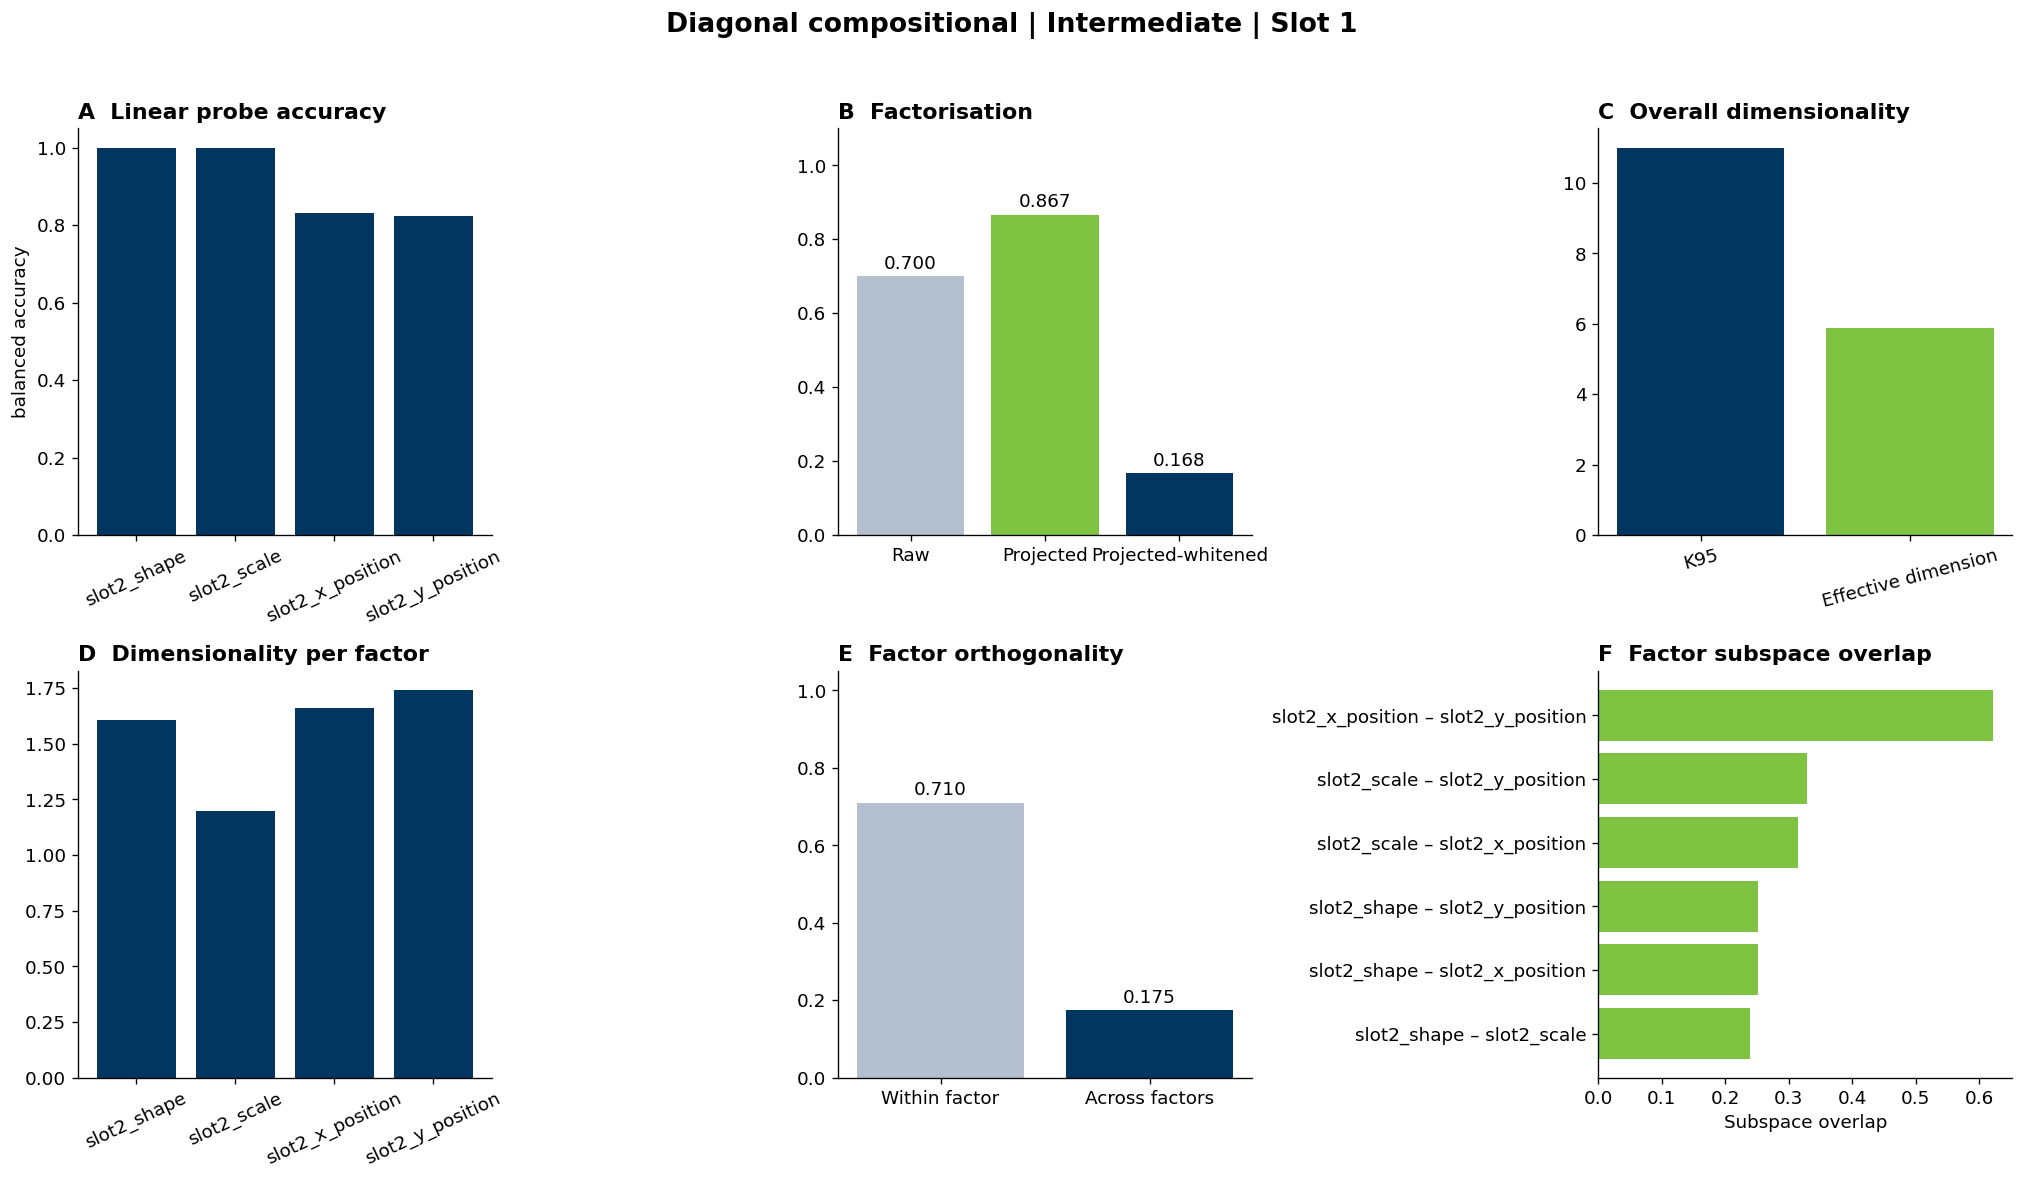

Dashboard saved to: /root/nfs/compositional-ood-generalization/DS/two-sprite-compositional-learning/analysis_results_gpu/diagonal_compositional/intermediate/slot2/representation_dashboard.png


In [7]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Locate the analysis results
# --------------------------------------------------

candidates = [
    Path.cwd() / "analysis_results_gpu",
    Path.home() / "nfs/compositional-ood-generalization/DS/two-sprite-compositional-learning/analysis_results_gpu",
    Path("/nfs/compositional-ood-generalization/DS/two-sprite-compositional-learning/analysis_results_gpu"),
    Path("/mnt/primary/compositional-ood-generalization/DS/two-sprite-compositional-learning/analysis_results_gpu"),
]

BASE_DIR = next((p for p in candidates if p.is_dir()), None)

if BASE_DIR is None:
    raise FileNotFoundError(
        "Cannot find analysis_results_gpu.\n"
        "Your notebook may be running outside the cluster. "
        "Transfer the results folder to this notebook environment "
        "or run the notebook on the cluster."
    )

DATA_DIR = BASE_DIR / "diagonal_compositional" / "intermediate" / "slot2"

if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"Analysis directory not found: {DATA_DIR}")

print("Reading from:", DATA_DIR.resolve())


# --------------------------------------------------
# 2. Load available CSV files
# --------------------------------------------------

def load_csv(filename):
    path = DATA_DIR / filename
    if path.exists():
        return pd.read_csv(path)
    print(f"Not available: {filename}")
    return None

factorisation = load_csv("factorisation.csv")
dimensionality = load_csv("overall_dimensionality.csv")
factor_dimensionality = load_csv("factor_dimensionality.csv")
orthogonality = load_csv("orthogonality_summary.csv")
leakage = load_csv("cross_slot_leakage.csv")
overlap = load_csv("factor_subspace_overlap.csv")
probes = load_csv("linear_probes.csv")


# --------------------------------------------------
# 3. Plot the metrics available in this analysis
# --------------------------------------------------

NAVY = "#003660"
GREEN = "#7FC342"
LIGHT = "#B4C0D0"
GREY = "#6B7280"

plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 120,
})

fig, axes = plt.subplots(2, 3, figsize=(17, 10))
axes = axes.ravel()

# A. Linear probe accuracy
ax = axes[0]

if probes is not None:
    metric = (
        "balanced_accuracy"
        if "balanced_accuracy" in probes.columns
        else "accuracy"
    )
    if {"factor", metric}.issubset(probes.columns):
        ax.bar(probes["factor"], probes[metric], color=NAVY)
        ax.set_ylim(0, 1.05)
        ax.set_ylabel(metric.replace("_", " "))
        ax.tick_params(axis="x", rotation=25)
    else:
        ax.text(0.5, 0.5, "Probe columns not recognised",
                ha="center", va="center", transform=ax.transAxes)
else:
    ax.text(0.5, 0.5, "No linear probe CSV",
            ha="center", va="center", transform=ax.transAxes)

ax.set_title("A  Linear probe accuracy", loc="left", fontweight="bold")


# B. Factorisation R²
ax = axes[1]

if factorisation is not None and len(factorisation):
    row = factorisation.iloc[0]
    cols = ["raw_r2", "projected_r2", "projected_whitened_r2"]
    if all(c in factorisation.columns for c in cols):
        values = [row[c] for c in cols]
        bars = ax.bar(
            ["Raw", "Projected", "Projected-whitened"],
            values,
            color=[LIGHT, GREEN, NAVY]
        )
        for bar, value in zip(bars, values):
            ax.text(bar.get_x() + bar.get_width()/2,
                    value + 0.02, f"{value:.3f}", ha="center")
        ax.set_ylim(0, 1.1)
    else:
        ax.text(0.5, 0.5, "R² columns not recognised",
                ha="center", va="center", transform=ax.transAxes)
else:
    ax.text(0.5, 0.5, "No factorisation data",
            ha="center", va="center", transform=ax.transAxes)

ax.set_title("B  Factorisation", loc="left", fontweight="bold")


# C. Overall dimensionality
ax = axes[2]

if dimensionality is not None and len(dimensionality):
    row = dimensionality.iloc[0]
    values = []
    labels = []
    for col, label in [
        ("k95", "K95"),
        ("effective_dimensionality", "Effective dimension"),
    ]:
        if col in dimensionality.columns:
            values.append(row[col])
            labels.append(label)

    if values:
        ax.bar(labels, values, color=[NAVY, GREEN][:len(values)])
        ax.tick_params(axis="x", rotation=15)
    else:
        ax.text(0.5, 0.5, "Dimensionality columns not recognised",
                ha="center", va="center", transform=ax.transAxes)
else:
    ax.text(0.5, 0.5, "No dimensionality data",
            ha="center", va="center", transform=ax.transAxes)

ax.set_title("C  Overall dimensionality", loc="left", fontweight="bold")


# D. Factor dimensionality
ax = axes[3]

if factor_dimensionality is not None and len(factor_dimensionality):
    df = factor_dimensionality
    if {"factor", "factor_effective_rank"}.issubset(df.columns):
        ax.bar(df["factor"], df["factor_effective_rank"], color=NAVY)
        ax.tick_params(axis="x", rotation=25)
        ax.set_ylabel("Effective rank")
    elif {"factor", "effective_rank"}.issubset(df.columns):
        ax.bar(df["factor"], df["effective_rank"], color=NAVY)
        ax.tick_params(axis="x", rotation=25)
    else:
        ax.text(0.5, 0.5, "Factor dimensionality columns not recognised",
                ha="center", va="center", transform=ax.transAxes)
else:
    ax.text(0.5, 0.5, "No factor dimensionality CSV",
            ha="center", va="center", transform=ax.transAxes)

ax.set_title("D  Dimensionality per factor", loc="left", fontweight="bold")


# E. Within-factor vs across-factor cosine
ax = axes[4]

if orthogonality is not None and len(orthogonality):
    row = orthogonality.iloc[0]
    cols = [
        "mean_within_factor_absolute_cosine",
        "mean_across_factor_absolute_cosine",
    ]
    if all(c in orthogonality.columns for c in cols):
        values = [row[c] for c in cols]
        bars = ax.bar(
            ["Within factor", "Across factors"],
            values,
            color=[LIGHT, NAVY]
        )
        for bar, value in zip(bars, values):
            ax.text(bar.get_x() + bar.get_width()/2,
                    value + 0.02, f"{value:.3f}", ha="center")
        ax.set_ylim(0, 1.05)
    else:
        ax.text(0.5, 0.5, "Orthogonality columns not recognised",
                ha="center", va="center", transform=ax.transAxes)
else:
    ax.text(0.5, 0.5, "No orthogonality summary CSV",
            ha="center", va="center", transform=ax.transAxes)

ax.set_title("E  Factor orthogonality", loc="left", fontweight="bold")


# F. Factor subspace overlap
ax = axes[5]

if overlap is not None and len(overlap):
    if {"factor_a", "factor_b", "subspace_overlap"}.issubset(overlap.columns):
        labels = (
            overlap["factor_a"].astype(str)
            + " – "
            + overlap["factor_b"].astype(str)
        )
        ax.barh(labels, overlap["subspace_overlap"], color=GREEN)
        ax.set_xlabel("Subspace overlap")
    else:
        ax.text(0.5, 0.5, "Subspace overlap columns not recognised",
                ha="center", va="center", transform=ax.transAxes)
else:
    ax.text(0.5, 0.5, "No subspace overlap CSV",
            ha="center", va="center", transform=ax.transAxes)

ax.set_title("F  Factor subspace overlap", loc="left", fontweight="bold")


# --------------------------------------------------
# 4. Finalise and save
# --------------------------------------------------

fig.suptitle(
    "Diagonal compositional | Intermediate | Slot 1",
    fontsize=16,
    fontweight="bold"
)

fig.tight_layout(rect=[0, 0, 1, 0.96])

output_path = DATA_DIR / "representation_dashboard.png"
fig.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()

print("Dashboard saved to:", output_path)


Reading from: /mnt/primary/compositional-ood-generalization/DS/two-sprite-compositional-learning/analysis_results_gpu/diagonal_compositional/intermediate/slot2


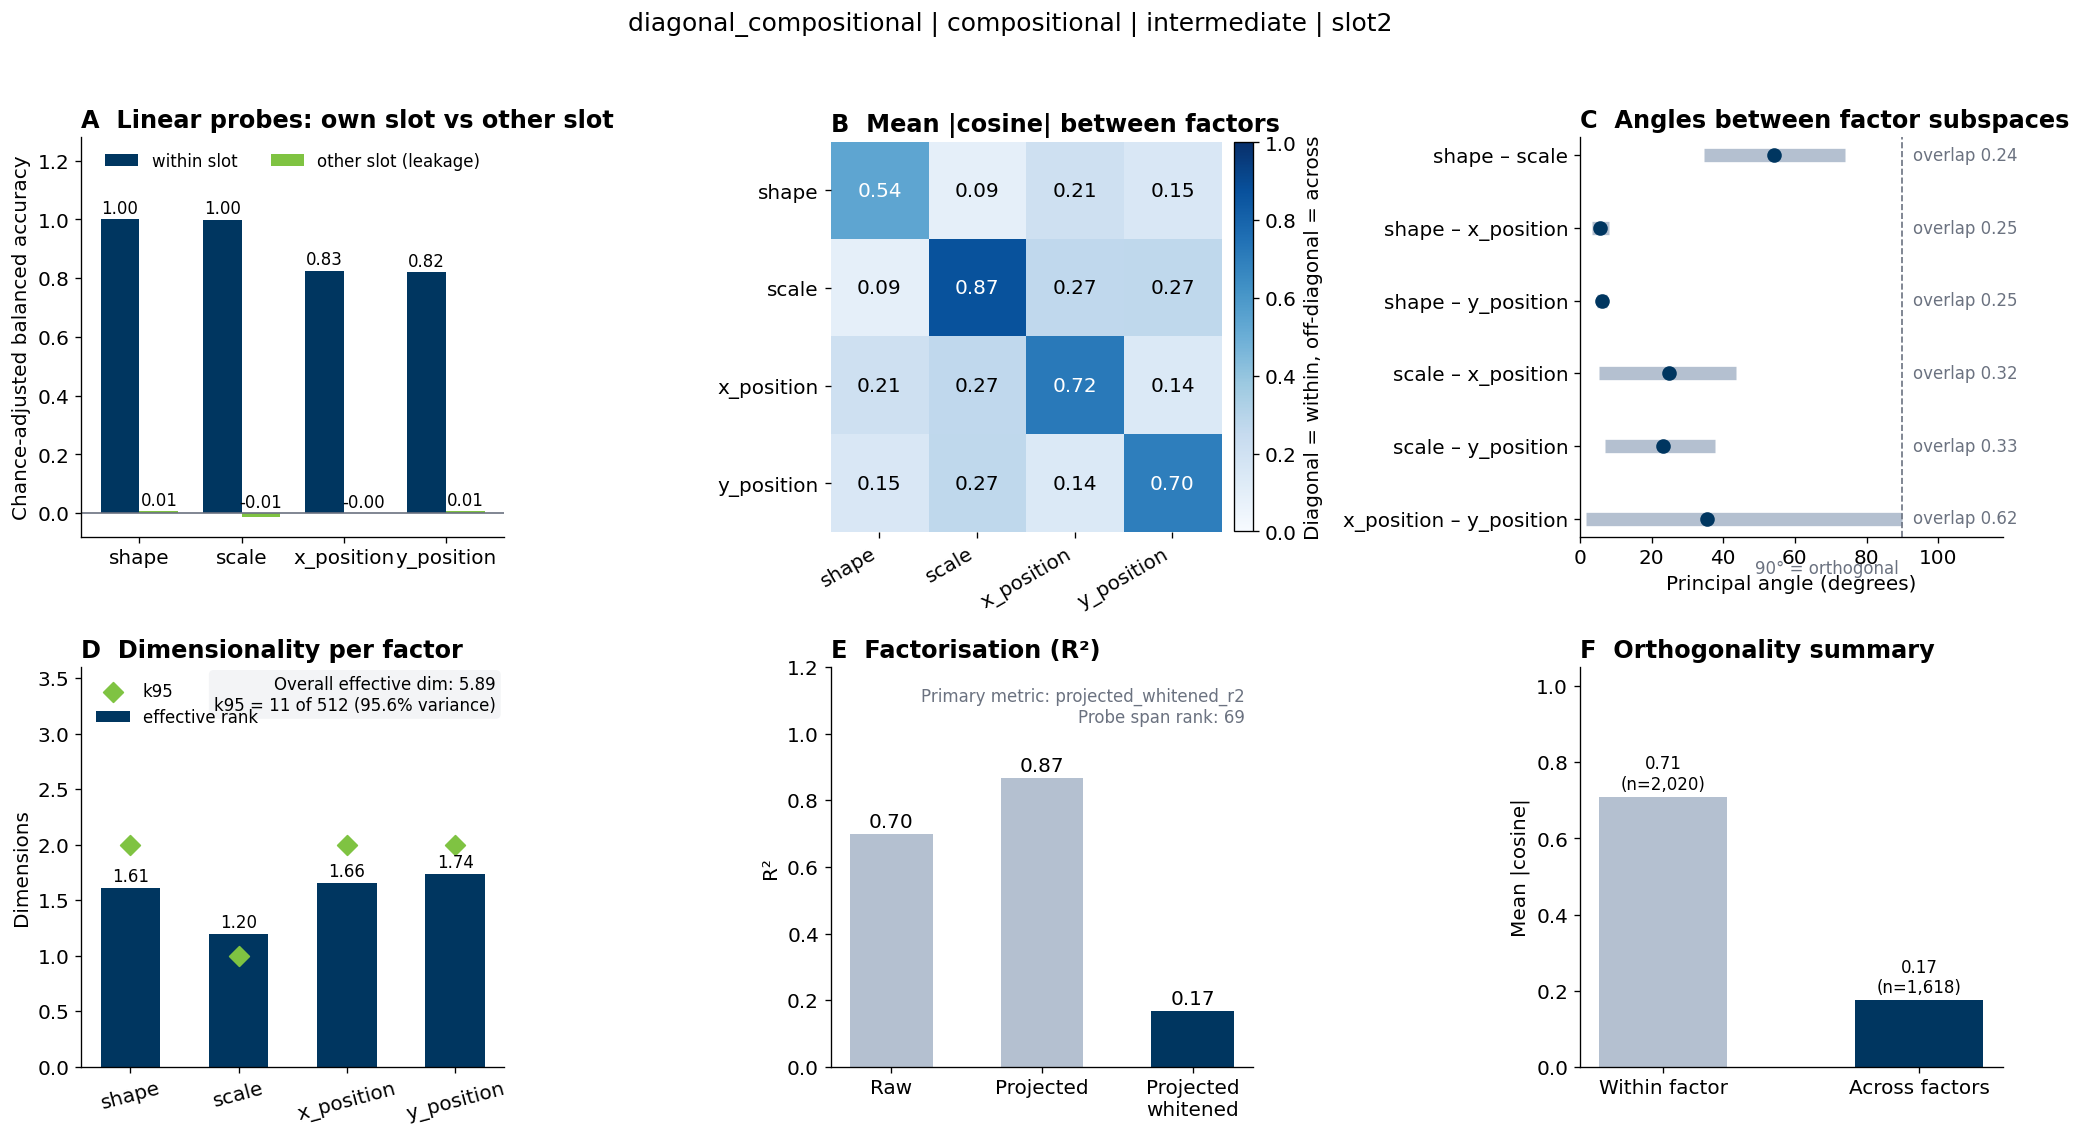

Dashboard saved to: /mnt/primary/compositional-ood-generalization/DS/two-sprite-compositional-learning/analysis_results_gpu/diagonal_compositional/intermediate/slot2/representation_dashboard.png


In [6]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Locate the analysis results
# --------------------------------------------------

candidates = [
    Path.cwd() / "analysis_results_gpu",
    Path.home() / "nfs/compositional-ood-generalization/DS/two-sprite-compositional-learning/analysis_results_gpu",
    Path("/nfs/compositional-ood-generalization/DS/two-sprite-compositional-learning/analysis_results_gpu"),
    Path("/mnt/primary/compositional-ood-generalization/DS/two-sprite-compositional-learning/analysis_results_gpu"),
]

BASE_DIR = next((p for p in candidates if p.is_dir()), None)

if BASE_DIR is None:
    raise FileNotFoundError(
        "Cannot find analysis_results_gpu. "
        "Make sure the results folder is accessible from this notebook."
    )

DATA_DIR = BASE_DIR / "diagonal_compositional" / "intermediate" / "slot2"

if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"Analysis directory not found: {DATA_DIR}")

print("Reading from:", DATA_DIR.resolve())


# --------------------------------------------------
# 2. Load CSV files
# --------------------------------------------------

required_files = [
    "cross_slot_leakage.csv",
    "factor_dimensionality.csv",
    "factor_subspace_overlap.csv",
    "factorisation.csv",
    "orthogonality_matrix.csv",
    "orthogonality_summary.csv",
    "overall_dimensionality.csv",
]

missing = [f for f in required_files if not (DATA_DIR / f).exists()]

if missing:
    raise FileNotFoundError(
        "The following CSV files are missing:\n"
        + "\n".join(missing)
        + "\n\nThe current analysis pipeline may need to export these files."
    )

leak = pd.read_csv(DATA_DIR / "cross_slot_leakage.csv")
fdim = pd.read_csv(DATA_DIR / "factor_dimensionality.csv")
ovl = pd.read_csv(DATA_DIR / "factor_subspace_overlap.csv")
fac = pd.read_csv(DATA_DIR / "factorisation.csv").iloc[0]
omat = pd.read_csv(DATA_DIR / "orthogonality_matrix.csv").set_index("factor")
osum = pd.read_csv(DATA_DIR / "orthogonality_summary.csv").iloc[0]
odim = pd.read_csv(DATA_DIR / "overall_dimensionality.csv").iloc[0]


# --------------------------------------------------
# 3. Plot styling and helper functions
# --------------------------------------------------

NAVY = "#003660"
GREEN = "#7FC342"
LIGHT = "#B4C0D0"
GREY = "#6B7280"

plt.rcParams.update({
    "font.size": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 120,
})

def short(name):
    """slot1_x_position -> x_position"""
    return name.split("_", 1)[1] if "_" in name else name


run_title = (
    f"{fac.condition} | {fac.architecture} | "
    f"{fac.level} | {fac.slot}"
)


# --------------------------------------------------
# 4. Panel A: Linear probes
# --------------------------------------------------

def plot_probes(ax, leak):
    x = np.arange(len(leak))
    w = 0.38

    within = leak.within_slot_adjusted_balanced_accuracy
    cross = leak.cross_slot_adjusted_balanced_accuracy

    ax.bar(x - w/2, within, w, color=NAVY, label="within slot")
    ax.bar(x + w/2, cross, w, color=GREEN, label="other slot (leakage)")

    for xi, a, b in zip(x, within, cross):
        ax.text(xi - w/2, a + 0.02, f"{a:.2f}", ha="center", fontsize=10)
        ax.text(xi + w/2, max(b, 0) + 0.02, f"{b:.2f}", ha="center", fontsize=10)

    ax.axhline(0, color=GREY, lw=1)
    ax.set_xticks(x, leak.target_factor)
    ax.set_ylim(-0.08, 1.28)
    ax.set_ylabel("Chance-adjusted balanced accuracy")
    ax.set_title("A  Linear probes: own slot vs other slot",
                 loc="left", fontweight="bold")
    ax.legend(frameon=False, loc="upper center", ncol=2, fontsize=10)


# --------------------------------------------------
# 5. Panel B: Orthogonality matrix
# --------------------------------------------------

def plot_orthogonality_matrix(ax, omat):
    labels = [short(c) for c in omat.columns]

    im = ax.imshow(omat.values, cmap="Blues", vmin=0, vmax=1)

    ax.set_xticks(range(len(labels)), labels, rotation=30, ha="right")
    ax.set_yticks(range(len(labels)), labels)

    for i in range(len(labels)):
        for j in range(len(labels)):
            v = omat.values[i, j]
            ax.text(
                j, i, f"{v:.2f}",
                ha="center", va="center",
                color="white" if v > 0.5 else "black"
            )

    ax.set_title("B  Mean |cosine| between factors",
                 loc="left", fontweight="bold")
    ax.spines[:].set_visible(False)

    return im


# --------------------------------------------------
# 6. Panel C: Principal angles
# --------------------------------------------------

def plot_principal_angles(ax, ovl):
    pair = [
        f"{short(a)} – {short(b)}"
        for a, b in zip(ovl.factor_a, ovl.factor_b)
    ]

    y = np.arange(len(ovl))[::-1]

    ax.hlines(
        y,
        ovl.minimum_principal_angle_degrees,
        ovl.maximum_principal_angle_degrees,
        color=LIGHT, lw=8
    )

    ax.scatter(
        ovl.mean_principal_angle_degrees,
        y, color=NAVY, zorder=3, s=60
    )

    ax.axvline(90, color=GREY, ls="--", lw=1)

    if len(y):
        ax.text(
            89, y.min() - 0.75,
            "90° = orthogonal",
            ha="right", color=GREY, fontsize=10
        )

    for yi, o in zip(y, ovl.subspace_overlap):
        ax.text(93, yi, f"overlap {o:.2f}",
                va="center", fontsize=10, color=GREY)

    ax.set_yticks(y, pair)
    ax.set_xlim(0, 118)
    ax.set_xlabel("Principal angle (degrees)")
    ax.set_title("C  Angles between factor subspaces",
                 loc="left", fontweight="bold")


# --------------------------------------------------
# 7. Panel D: Dimensionality
# --------------------------------------------------

def plot_dimensionality(ax, fdim, odim):
    f = [short(n) for n in fdim.factor]
    xx = np.arange(len(f))

    ax.bar(
        xx, fdim.effective_rank,
        color=NAVY, width=0.55,
        label="effective rank"
    )

    ax.scatter(
        xx, fdim.k95,
        marker="D", color=GREEN,
        s=70, zorder=3, label="k95"
    )

    for xi, er in zip(xx, fdim.effective_rank):
        ax.text(xi, er + 0.06, f"{er:.2f}",
                ha="center", fontsize=10)

    ax.set_xticks(xx, f, rotation=15)
    ax.set_ylim(
        0,
        max(fdim.k95.max(), fdim.effective_rank.max()) + 1.6
    )
    ax.set_ylabel("Dimensions")
    ax.set_title("D  Dimensionality per factor",
                 loc="left", fontweight="bold")
    ax.legend(frameon=False, loc="upper left", fontsize=10)

    ax.text(
        0.98, 0.98,
        f"Overall effective dim: {odim.effective_dimensionality:.2f}\n"
        f"k95 = {int(odim.k95)} of {int(odim.total_components)} "
        f"({odim.variance_explained_by_k95:.1%} variance)",
        transform=ax.transAxes,
        ha="right", va="top", fontsize=10,
        bbox=dict(boxstyle="round", fc="#F3F4F6", ec="none")
    )


# --------------------------------------------------
# 8. Panel E: Factorisation R²
# --------------------------------------------------

def plot_factorisation(ax, fac):
    names = ["Raw", "Projected", "Projected\nwhitened"]

    vals = [
        fac.raw_r2,
        fac.projected_r2,
        fac.projected_whitened_r2
    ]

    bars = ax.bar(
        names, vals,
        color=[LIGHT, LIGHT, NAVY],
        width=0.55
    )

    for b, v in zip(bars, vals):
        ax.text(
            b.get_x() + b.get_width()/2,
            v + 0.02,
            f"{v:.2f}",
            ha="center"
        )

    ax.set_ylim(0, 1.2)
    ax.set_ylabel("R²")
    ax.set_title("E  Factorisation (R²)",
                 loc="left", fontweight="bold")

    ax.text(
        0.98, 0.95,
        f"Primary metric: {fac.primary_factorisation_metric}\n"
        f"Probe span rank: {int(fac.probe_span_rank)}",
        transform=ax.transAxes,
        ha="right", va="top",
        fontsize=10, color=GREY
    )


# --------------------------------------------------
# 9. Panel F: Orthogonality summary
# --------------------------------------------------

def plot_orthogonality_summary(ax, osum):
    vals = [
        osum.mean_within_factor_absolute_cosine,
        osum.mean_across_factor_absolute_cosine
    ]

    ns = [
        osum.n_within_comparisons,
        osum.n_across_comparisons
    ]

    bars = ax.bar(
        ["Within factor", "Across factors"],
        vals,
        color=[LIGHT, NAVY],
        width=0.5
    )

    for b, v, n in zip(bars, vals, ns):
        ax.text(
            b.get_x() + b.get_width()/2,
            v + 0.02,
            f"{v:.2f}\n(n={int(n):,})",
            ha="center", fontsize=10
        )

    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Mean |cosine|")
    ax.set_title("F  Orthogonality summary",
                 loc="left", fontweight="bold")


# --------------------------------------------------
# 10. Create the six-panel dashboard
# --------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(17, 9.5))
ax = axes.ravel()

plot_probes(ax[0], leak)

im = plot_orthogonality_matrix(ax[1], omat)
cb = fig.colorbar(im, ax=ax[1], fraction=0.046, pad=0.03)
cb.set_label("Diagonal = within, off-diagonal = across")

plot_principal_angles(ax[2], ovl)
plot_dimensionality(ax[3], fdim, odim)
plot_factorisation(ax[4], fac)
plot_orthogonality_summary(ax[5], osum)

fig.suptitle(run_title, fontsize=15, y=0.995)
fig.tight_layout(rect=(0, 0, 1, 0.97))


# --------------------------------------------------
# 11. Save and display
# --------------------------------------------------

output_path = DATA_DIR / "representation_dashboard.png"

fig.savefig(
    output_path,
    dpi=200,
    facecolor="white",
    bbox_inches="tight"
)

plt.show()

print("Dashboard saved to:", output_path.resolve())


Reading from: /mnt/primary/compositional-ood-generalization/DS/two-sprite-compositional-learning/analysis_results_gpu/diagonal_compositional/intermediate/slot2
Linear probe results: 4 rows
Orthogonality comparisons: 10 rows


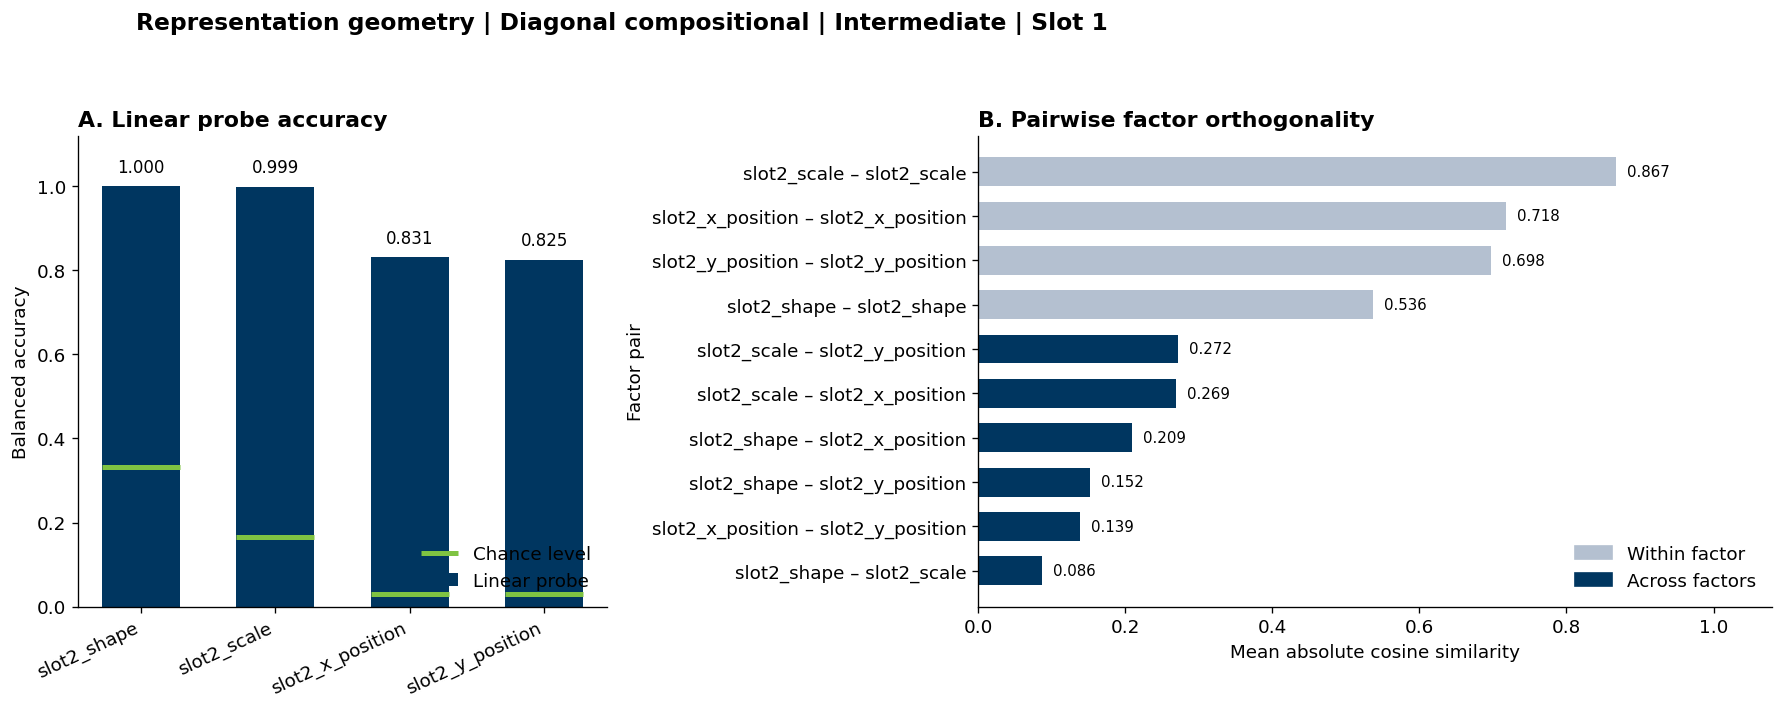

Figure saved to: /mnt/primary/compositional-ood-generalization/DS/two-sprite-compositional-learning/analysis_results_gpu/diagonal_compositional/intermediate/slot2/probe_orthogonality_dashboard.png


In [5]:

# --------------------------------------------------
# 1. Locate analysis results
# --------------------------------------------------

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

candidates = [
    Path.cwd() / "analysis_results_gpu",
    Path.home() / "nfs/compositional-ood-generalization/DS/two-sprite-compositional-learning/analysis_results_gpu",
    Path("/nfs/compositional-ood-generalization/DS/two-sprite-compositional-learning/analysis_results_gpu"),
    Path("/mnt/primary/compositional-ood-generalization/DS/two-sprite-compositional-learning/analysis_results_gpu"),
]

BASE_DIR = next((p for p in candidates if p.is_dir()), None)

if BASE_DIR is None:
    raise FileNotFoundError("Cannot find analysis_results_gpu.")

DATA_DIR = BASE_DIR / "diagonal_compositional" / "intermediate" / "slot2"

if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"Analysis directory not found: {DATA_DIR}")

print("Reading from:", DATA_DIR.resolve())


# --------------------------------------------------
# 2. Load CSV files
# --------------------------------------------------

probes = pd.read_csv(DATA_DIR / "linear_probes.csv")
orthogonality_pairs = pd.read_csv(DATA_DIR / "orthogonality_pairs.csv")

print("Linear probe results:", len(probes), "rows")
print("Orthogonality comparisons:", len(orthogonality_pairs), "rows")


# --------------------------------------------------
# 3. Plot styling
# --------------------------------------------------

NAVY = "#003660"
GREEN = "#7FC342"
LIGHT = "#B4C0D0"
GREY = "#6B7280"

plt.rcParams.update({
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 120,
})


# --------------------------------------------------
# 4. Prepare labels
# --------------------------------------------------

factor_labels = {
    "slot1_shape": "Shape",
    "slot1_scale": "Scale",
    "slot1_x_position": "X position",
    "slot1_y_position": "Y position",
}

probes = probes.copy()
probes["label"] = probes["factor"].map(factor_labels).fillna(probes["factor"])

pairs = orthogonality_pairs.copy()

pairs["pair"] = (
    pairs["factor_a"].str.replace("slot1_", "", regex=False)
    + " – "
    + pairs["factor_b"].str.replace("slot1_", "", regex=False)
)

pairs["colour"] = pairs["comparison_type"].map({
    "within": LIGHT,
    "across": NAVY
})

pairs = pairs.sort_values("mean_absolute_cosine", ascending=True)


# --------------------------------------------------
# 5. Create two-panel figure
# --------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 6),
    gridspec_kw={"width_ratios": [1, 1.5]}
)


# --------------------------------------------------
# Panel A: Linear probe accuracy
# --------------------------------------------------

ax = axes[0]

x = np.arange(len(probes))
width = 0.58

bars = ax.bar(
    x,
    probes["balanced_accuracy"],
    width=width,
    color=NAVY,
    label="Linear probe"
)

# Factor-specific chance baselines
for i, chance in enumerate(probes["chance_balanced_accuracy"]):
    ax.hlines(
        chance,
        i - width / 2,
        i + width / 2,
        color=GREEN,
        linewidth=3,
        label="Chance level" if i == 0 else None
    )

# Value labels
for bar, value in zip(bars, probes["balanced_accuracy"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.025,
        f"{value:.3f}",
        ha="center",
        va="bottom",
        fontsize=10
    )

ax.set_xticks(x)
ax.set_xticklabels(probes["label"], rotation=25, ha="right")
ax.set_ylim(0, 1.12)
ax.set_ylabel("Balanced accuracy")
ax.set_title("A. Linear probe accuracy", loc="left", fontweight="bold")
ax.legend(frameon=False, loc="lower right")


# --------------------------------------------------
# Panel B: Pairwise factor orthogonality
# --------------------------------------------------

ax = axes[1]

bars = ax.barh(
    pairs["pair"],
    pairs["mean_absolute_cosine"],
    color=pairs["colour"],
    height=0.65
)

for bar, value in zip(bars, pairs["mean_absolute_cosine"]):
    ax.text(
        value + 0.015,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.3f}",
        va="center",
        fontsize=9
    )

ax.set_xlim(0, 1.08)
ax.set_xlabel("Mean absolute cosine similarity")
ax.set_ylabel("Factor pair")
ax.set_title("B. Pairwise factor orthogonality", loc="left", fontweight="bold")

ax.legend(
    handles=[
        Patch(color=LIGHT, label="Within factor"),
        Patch(color=NAVY, label="Across factors")
    ],
    frameon=False,
    loc="lower right"
)


# --------------------------------------------------
# 6. Figure title, layout and save
# --------------------------------------------------

fig.suptitle(
    "Representation geometry | Diagonal compositional | Intermediate | Slot 1",
    fontsize=14,
    fontweight="bold",
    x=0.08,
    ha="left"
)

plt.tight_layout(rect=[0, 0, 1, 0.93])

output_path = DATA_DIR / "probe_orthogonality_dashboard.png"

fig.savefig(
    output_path,
    dpi=300,
    facecolor="white",
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", output_path.resolve())
